In [131]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

import pandas as pd

np.random.seed(42)
random.seed(42)

class SISModel:
    def __init__(self, N, populations, beta, mu, p, timesteps, initial_infected, alpha, average_degree):
        self.N = N
        self.populations = populations  # 每个patch的人口不同
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.timesteps = timesteps
        self.initial_infected = initial_infected
        self.average_degree = average_degree

        # 创建包含不同人口数量的patch

        # 创建一个包含 N 个元素的列表，其中每个元素是一个大小为 populations[i] 的全零数组
        self.patches = [np.zeros(self.populations[i]) for i in range(N)]
        self.infection_history = np.zeros((timesteps, N))
        self.total_infected_history = np.zeros(timesteps)  # 记录每个时间步的总感染人数

        # 生成具有给定平均度的Watts-Strogatz小世界网络
        self.G = nx.watts_strogatz_graph(N, 4, 0.8)

        # 为每条边分配1到10之间的随机权重
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

        self.rho = np.zeros(N)
        self._initialize_patches()

    def _initialize_patches(self):
        # 每个patch初始感染人数为10
        for i in range(self.N):
            infected_indices = np.random.choice(self.populations[i], self.initial_infected, replace=False)
            self.patches[i][infected_indices] = 1
            self.rho[i] = np.sum(self.patches[i]) / self.populations[i]

    def _get_Pi_i(self):
        # 计算每个patch的感染概率Πi
        R_i = np.zeros(self.N)
        D_i = np.zeros(self.N)
        P_i = np.zeros(self.N)
        Pi_i = np.zeros(self.N)
        new_rho = np.zeros(self.N)
        for i in range(self.N):
            R_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * self.rho[j] for j in range(self.N)]))
            D_i[i] = 1 - (1 - self.beta) ** ((1 - self.p) * self.populations[i] * self.rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.populations[j] * self.rho[j] for j in range(self.N)]))
            P_i[i] = self.alpha * R_i[i] + (1 - self.alpha) * D_i[i]
        for i in range(self.N):
            Pi_i[i] = (1 - self.p) * P_i[i] + self.p * np.sum([self.C[i, j] * P_i[j] for j in range(self.N)])
            new_rho[i] = (1 - self.mu) * self.rho[i] + (1 - self.rho[i]) * Pi_i[i]
        self.Pi_i = Pi_i
        self.rho = new_rho

    def _infection_process(self, patch_index, current_patch):
        # 处理感染过程
        for j in range(len(current_patch)):
            if current_patch[j] == 0 and np.random.rand() < self.Pi_i[patch_index]:
                current_patch[j] = 1
        return current_patch

    def _recovery_process(self, current_patch):
        # 处理恢复过程
        for j in range(len(current_patch)):
            if current_patch[j] == 1 and np.random.rand() < self.mu:
                current_patch[j] = 0
        return current_patch

    def run_simulation(self):
        for t in range(self.timesteps):
            self._get_Pi_i()
            total_infected = 0  # 记录当前时间步的总感染人数
            for i in range(self.N):
                current_patch = self.patches[i]
                current_patch = self._infection_process(i, current_patch)
                current_patch = self._recovery_process(current_patch)
                self.patches[i] = current_patch
                self.infection_history[t, i] = np.sum(current_patch)
                total_infected += np.sum(current_patch)
            self.total_infected_history[t] = total_infected  # 记录总感染人数

    # def plot_results(self, results, degrees):
    #     plt.figure(figsize=(10, 6))
    #     for i, degree in enumerate(degrees):
    #         plt.plot(results[i], label=f'平均度 = {degree}')
    #     plt.xlabel('时间')
    #     plt.ylabel('总受感染人数')
    #     plt.legend()
    #     plt.title('不同平均度下的总受感染人数随时间变化')
    #     plt.grid(True)
    #     plt.show()


# 参数设置
N = 50
population_per_patch = np.full(N, 100)
mu = 0.1
p = 0.6
timesteps = 500
initial_infected = 5
alpha = 0.6
average_degrees = [10, 20, 30]
betas = [0.001608, 0.00402]  # 两个不同的beta值
num_simulations = 10  # 模拟次数

# 针对不同平均度和不同beta运行模拟并记录结果
all_results = []

for beta in betas:
    for avg_degree in average_degrees:
        degree_results = np.zeros((num_simulations, timesteps))
        for sim in range(num_simulations):
            model = SISModel(N=N, populations=population_per_patch, beta=beta, mu=mu, p=p, timesteps=timesteps, 
                             initial_infected=initial_infected, alpha=alpha, average_degree=avg_degree)
            model.run_simulation()
            degree_results[sim, :] = model.total_infected_history
        avg_result = np.mean(degree_results, axis=0)
        # 将beta, avg_degree和avg_result（timesteps个值）作为一行展开放入
        all_results.append([beta, avg_degree] + avg_result.tolist())

# 创建包含 timesteps 列的 DataFrame
columns = ['beta', 'avg_degree'] + [f'timestep_{i}' for i in range(timesteps)]
all_results_df = pd.DataFrame(all_results, columns=columns)

# 保存结果为 CSV
all_results_df.to_csv('1013_test_results.csv', index=False)


In [132]:
print(all_results_df)

# len(all_results['total_infected_history'].values[0])
# all_results['total_infected_history'].values[0][2]

# degree_results = np.zeros((2, 5))
# avg_result = np.mean(degree_results, axis=0)
# print(avg_result)
# avg_result.tolist()
# avg_result

       beta  avg_degree  timestep_0  timestep_1  timestep_2  timestep_3  \
0  0.001608          10       247.1       239.4       233.1       227.9   
1  0.001608          20       241.4       235.4       228.9       225.8   
2  0.001608          30       246.5       245.9       242.4       239.5   
3  0.004020          10       264.7       288.7       312.3       335.3   
4  0.004020          20       274.4       301.0       330.7       362.3   
5  0.004020          30       281.0       309.8       341.0       386.8   

   timestep_4  timestep_5  timestep_6  timestep_7  ...  timestep_490  \
0       220.4       215.4       208.8       202.9  ...           0.1   
1       221.1       219.4       213.3       209.1  ...          12.4   
2       234.5       234.6       234.4       232.2  ...         127.6   
3       360.1       388.9       414.4       443.3  ...        2148.4   
4       402.1       441.3       487.2       531.7  ...        2425.8   
5       434.5       489.1       547.0     

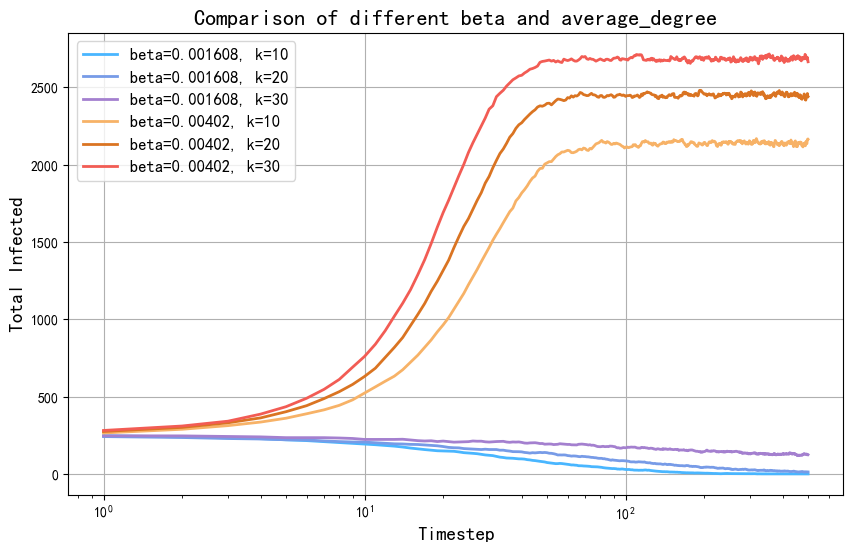

In [137]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 读取保存的结果
all_results = pd.read_csv('1013_test_results.csv')

# 获取时间步长
timesteps = len([col for col in all_results.columns if 'timestep_' in col])

# 使用 arange 从 1 到 timesteps 确保x轴从1开始
time_range = np.arange(1, timesteps + 1)

# 绘制不同 beta 和 k 的曲线
plt.figure(figsize=(10, 6))

# 提取不同组合的时间序列数据并绘制曲线
sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 10), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#49b6ff',
    label='beta=0.001608, k=10'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 20), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#779be7',
    label='beta=0.001608, k=20'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 30), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#a480cf',
    label='beta=0.001608, k=30'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 10), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#f7b267',
    label='beta=0.00402, k=10'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 20), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#da7422',
    label='beta=0.00402, k=20'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 30), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#f25c54',
    label='beta=0.00402, k=30'
)

# 设置对数刻度和标签
plt.xlabel('Timestep', fontsize=14)
plt.xscale('log')
plt.ylabel('Total Infected', fontsize=14)
plt.title('Comparison of different beta and average_degree', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


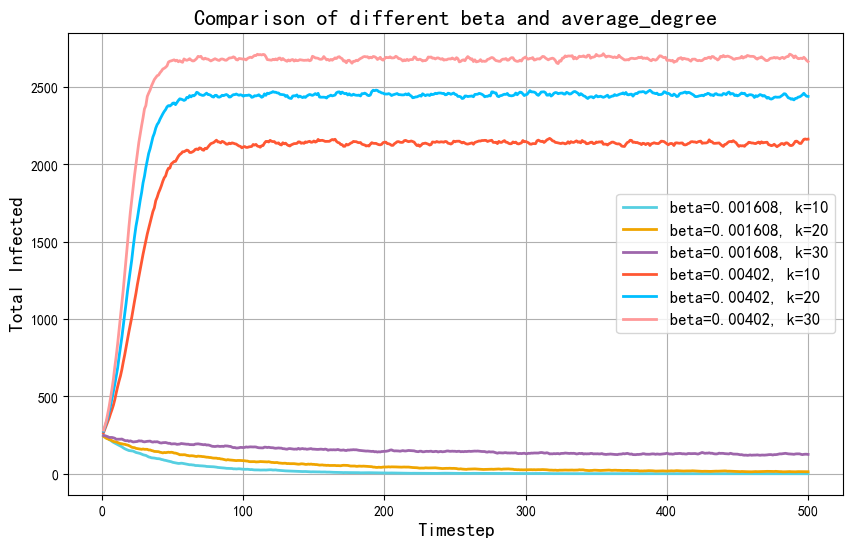

In [134]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 读取保存的结果
all_results = pd.read_csv('1013_test_results.csv')

# 获取时间步长
timesteps = len([col for col in all_results.columns if 'timestep_' in col])

# 使用 arange 从 1 到 timesteps 确保x轴从1开始
time_range = np.arange(1, timesteps + 1)

# 绘制不同 beta 和 k 的曲线
plt.figure(figsize=(10, 6))

# 提取不同组合的时间序列数据并绘制曲线
sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 10), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#56cfe1',
    label='beta=0.001608, k=10'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 20), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#f0a500',
    label='beta=0.001608, k=20'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.001608) & (all_results['avg_degree'] == 30), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#9e66ab',
    label='beta=0.001608, k=30'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 10), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#ff5733',
    label='beta=0.00402, k=10'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 20), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#00bfff',
    label='beta=0.00402, k=20'
)

sns.lineplot(
    x=time_range,  
    y=all_results.loc[(all_results['beta'] == 0.00402) & (all_results['avg_degree'] == 30), [f'timestep_{i}' for i in range(timesteps)]].values.flatten(), 
    linewidth=2, 
    markersize=5, 
    color='#ff9999',
    label='beta=0.00402, k=30'
)

# 设置对数刻度和标签
plt.xlabel('Timestep', fontsize=14)
plt.ylabel('Total Infected', fontsize=14)
plt.title('Comparison of different beta and average_degree', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()
